# Supplementary Figure 2. Off states are not produced by the read-out noise alone

The fitted model with a constant common input (no dips), read out in two ways: with the same gains as the fitted
model (the identical read-out applied to a network that never falls silent), and with the gains recalibrated to
the data's decoding strength. Fit loss as used for fitting (`readout.loss`). About 3 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nmdaint import ratemodel, readout
from plots import figS2, style

## Parameters

In [2]:
P = ratemodel.params('nmda')
CONTROL = dict(dip_depth=0.0)      # the control: no dips; e.g. dict(dip_rate=2.0) for rare dips
LABELS = [('Fitted model (dips)', 'Dips'), ('No dips, same gain', 'No dips\nsame gain'),     # legend and bar labels
          ('No dips, recalibrated', 'No dips\nrecalib.')]
N_TRIALS, SEED = 2112, 1

## The fitted model and the control

In [3]:
ses, hist = readout.load_data()
fitted = readout.evaluate(P, ses, n_trials=N_TRIALS, seed=SEED)
gains = {lab: r['gain'] for lab, r in fitted['sets'].items()}
control = {**P, **CONTROL}
same_gain = readout.evaluate(control, ses, seed=2, sim=ratemodel.simulate(control, N_TRIALS, seed=SEED * 100 + 1), gains=gains)
recalibrated = readout.evaluate(control, ses, n_trials=N_TRIALS, seed=SEED)
conds = [(label, short, readout.summary(o, ses, hist)) for (label, short), o in zip(LABELS, (fitted, same_gain, recalibrated))]
for label, _, s in conds:
    print(f'{label}: fit loss summed over the 7 populations {s.loss.sum():.0f}; memory held {s.memory.iloc[0]:.3f}')
{label: s.n_off.round(2) for label, _, s in conds}

Fitted model (dips): fit loss summed over the 7 populations 74; memory held 0.984
No dips, same gain: fit loss summed over the 7 populations 3248; memory held 1.000
No dips, recalibrated: fit loss summed over the 7 populations 313; memory held 1.000


{'Fitted model (dips)': set
 top 5      2.49
 top 20     2.51
 top 50     2.68
 rand 5     4.48
 rand 20    4.18
 rand 50    3.91
 all        3.10
 Name: n_off, dtype: float64,
 'No dips, same gain': set
 top 5      0.00
 top 20     0.00
 top 50     0.00
 rand 5     2.10
 rand 20    0.53
 rand 50    0.11
 all        0.00
 Name: n_off, dtype: float64,
 'No dips, recalibrated': set
 top 5      0.08
 top 20     0.10
 top 50     0.27
 rand 5     4.77
 rand 20    4.50
 rand 50    3.95
 all        2.37
 Name: n_off, dtype: float64}

One trial of the fitted model and of the control, and its z with the three read-outs.

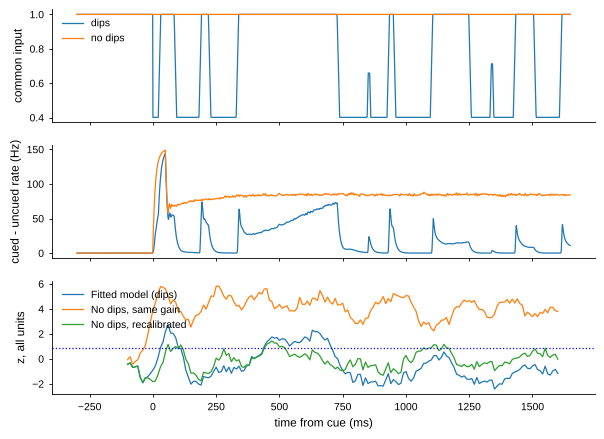

In [4]:
_, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
for o, name in ((fitted, 'dips'), (same_gain, 'no dips')):
    ax[0].plot(o['sim']['t'], o['sim']['m'][0], label=name)
    ax[1].plot(o['sim']['t'], o['sim']['rc'][0] - o['sim']['ru'][0], label=name)
for o, (label, _) in zip((fitted, same_gain, recalibrated), LABELS):
    ax[2].plot(o['tz'], o['sets']['all']['z'][0], label=label)
ax[2].axhline(0.84, color='b', ls=':')
ax[0].set_ylabel('common input'); ax[1].set_ylabel('cued - uncued rate (Hz)'); ax[2].set_ylabel('z, all units')
ax[2].set_xlabel('time from cue (ms)'); ax[0].legend(); ax[2].legend();

## Play: Off states against the depth of the dips
Recalibrated read-out of all units, 500 trials per depth. Off states remain without dips (noise alone), but fewer
than in the data.

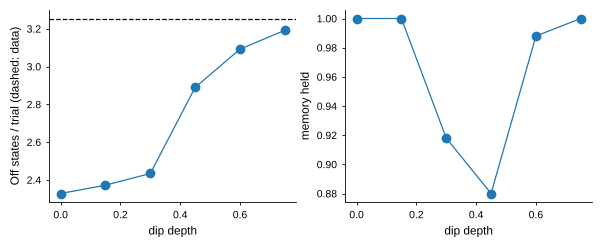

In [5]:
depths = (0.0, 0.15, 0.3, 0.45, 0.6, 0.75)
sweep = [readout.evaluate({**P, 'dip_depth': x}, ses, n_trials=500, seed=SEED, sets=('all',)) for x in depths]
_, ax = plt.subplots(1, 2, figsize=(7, 2.5))
ax[0].plot(depths, [o['sets']['all']['n_off'] for o in sweep], 'o-'); ax[0].axhline(ses['all']['off_per_trial'].mean(), color='k', ls='--')
ax[0].set_ylabel('Off states / trial (dashed: data)')
ax[1].plot(depths, [o['mem'] for o in sweep], 'o-'); ax[1].set_ylabel('memory held')
for a in ax:
    a.set_xlabel('dip depth')

## Figure

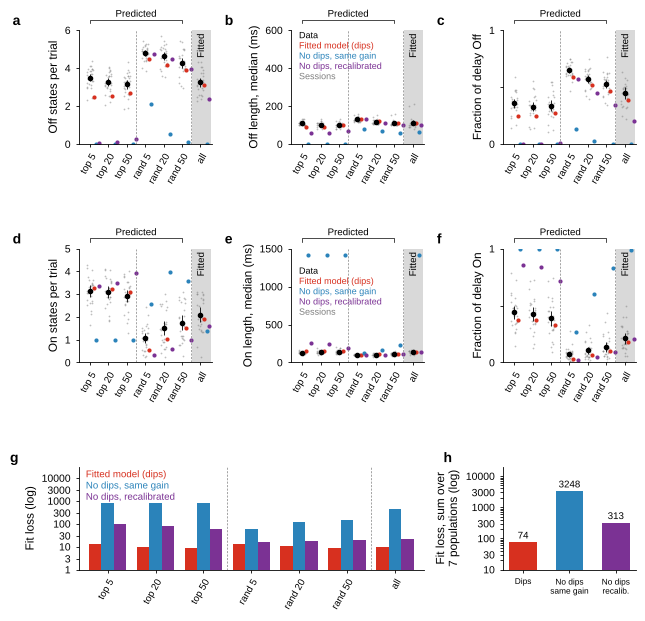

In [6]:
fig = figS2.draw(ses, conds)
style.save(fig, '../figures/figS2.png')